Question 4.1 Random protocol: a stratified random split with 70 % of the videos for training and 30 % for testing, 
repeated 30 times with a fixed seed (StratifiedShuffleSplit). Report the mean and standard 
deviation of accuracy and macro F1, and the confusion matrix summed over the repetitions.

In [ ]:

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

# Load video-level features and held-out test-video IDs
video_data = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

# Exclude held-out test actors
dev_data = video_data[
    ~video_data["video"].isin(testIndex["video"])
].copy()

# Separate feature matrix X and target labels y
feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]

X = dev_data[feature_cols]
y = dev_data["emotion"]

classes = sorted(y.unique())

# Sanity checks
print("Development videos:", len(dev_data))
print("Number of features:", len(feature_cols))
print("Emotion counts:\n", y.value_counts())

# Required pipeline: scale features, then train an RBF SVM
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

splitter = StratifiedShuffleSplit(
    n_splits=30,
    test_size=0.30,
    random_state=42
)

accuracies = []
macro_f1_scores = []
summed_cm = np.zeros((len(classes), len(classes)), dtype=int)

for train_idx, test_idx in splitter.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    accuracies.append(accuracy_score(y_test, y_pred))
    macro_f1_scores.append(
        f1_score(y_test, y_pred, average="macro")
    )

    summed_cm += confusion_matrix(
        y_test, y_pred, labels=classes
    )

print(f"Accuracy: {np.mean(accuracies):.3f} ± {np.std(accuracies):.3f}")
print(f"Macro F1: {np.mean(macro_f1_scores):.3f} ± {np.std(macro_f1_scores):.3f}")
print("Class order:", classes)
print("Summed confusion matrix:\n", summed_cm)


Development videos: 1200
Number of features: 55
Emotion counts:
 emotion
Calm         160
Happy        160
Sad          160
Angry        160
Fearful      160
Disgust      160
Surprised    160
Neutral       80
Name: count, dtype: int64
Accuracy: 0.763 ± 0.024
Macro F1: 0.761 ± 0.023
Class order: ['Angry', 'Calm', 'Disgust', 'Fearful', 'Happy', 'Neutral', 'Sad', 'Surprised']
Summed confusion matrix:
 [[1136    5   61   44    0   13   51  130]
 [  22 1266    4    8   18   69   48    5]
 [  77   26 1198   16   10    8   67   38]
 [  82    8   26 1017   21    6  155  125]
 [  36  145    1    0 1241    0    1   16]
 [   3   33    0   27    0  592   57    8]
 [   8   70  117   67   38  115  941   84]
 [  73   40   60  234   23   62  100  848]]


The mean accuracy was 0.763 ± 0.024, while the mean macro F1-score was 0.761 ± 0.023. The relatively small standard deviations indicate that the results were reasonably consistent across the random splits.

As for the confusion matrix, Calm, Disgust and Happy were classified relatively well. Surprised was often mistaken for Fearful and less often as Sad. Sad was often mistaken for Neutral or Disgust. Fearfull was often mistaken for Sad or Surprised. Angry got often mistaken for surprized. And finally, even though it was relatively well classified, Happy was also often mistaken for Calm.

Question 4.2 Leave-one-subject-out (LOSO) protocol: LeaveOneGroupOut with the actor as the group, 20 folds, 
one per development actor. Report the same metrics, and the distribution of the macro F1 over the 
20 actors.

Development videos: 1200
Number of features: 55
Emotion counts:
 emotion
Calm         160
Happy        160
Sad          160
Angry        160
Fearful      160
Disgust      160
Surprised    160
Neutral       80
Name: count, dtype: int64
Mean accuracy: 0.592 ± 0.113
Mean macro F1: 0.568 ± 0.122

Class order: ['Angry', 'Calm', 'Disgust', 'Fearful', 'Happy', 'Neutral', 'Sad', 'Surprised']
Summed confusion matrix:
 [[117   0  11   8   0   2   5  17]
 [  6 103   1   3  14  13  18   2]
 [ 13   8  98   6   8   2  13  12]
 [ 18   4   8  90   3   5  20  12]
 [  7  27   3   0 113   1   1   8]
 [  0   5   1   4   1  57  10   2]
 [  3  13  17  18  10  17  68  14]
 [ 12   6  16  29   4  13  16  64]]

Results for each held-out actor:
actor  accuracy  macro_f1
   02  0.583333  0.537703
   03  0.616667  0.526129
   04  0.533333  0.512707
   05  0.600000  0.540506
   06  0.450000  0.351247
   07  0.633333  0.574444
   08  0.616667  0.543560
   09  0.666667  0.674200
   10  0.883333  0.881387
   11  0.400

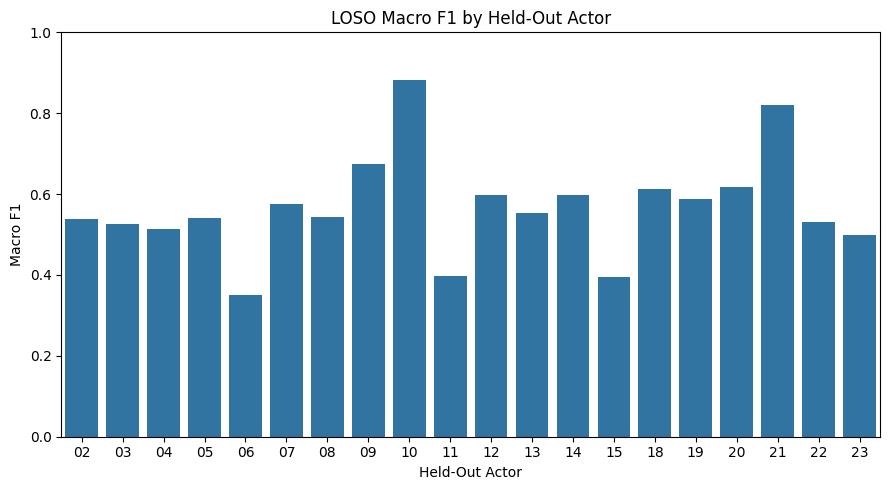

In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load video-level features and held-out test-video IDs
video_data = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

# Exclude held-out test actors
dev_data = video_data[
    ~video_data["video"].isin(testIndex["video"])
].copy()

# Extract actor ID from the video filename
dev_data["actor"] = (
    dev_data["video"]
    .str.replace(".csv", "", regex=False)
    .str.split("-")
    .str[-1]
)

# Separate feature matrix X and target labels y
feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

# Sanity checks
print("Development videos:", len(dev_data))
print("Number of features:", len(feature_cols))
print("Emotion counts:\n", y.value_counts())

# Required pipeline: scale features, then train an RBF SVM
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

logo = LeaveOneGroupOut()
classes = sorted(y.unique())

accuracies = []
macro_f1_scores = []
summed_cm = np.zeros((len(classes), len(classes)), dtype=int)
actor_results = []

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Identify the actor held out in this fold
    held_out_actor = groups.iloc[test_idx].iloc[0]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred,
        average="macro",
        labels=classes,
        zero_division=0
    )

    accuracies.append(accuracy)
    macro_f1_scores.append(macro_f1)

    actor_results.append({
        "actor": held_out_actor,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    summed_cm += confusion_matrix(
        y_test, y_pred, labels=classes
    )

# Overall results across the 20 held-out actors
print(f"Mean accuracy: {np.mean(accuracies):.3f} ± {np.std(accuracies):.3f}")
print(f"Mean macro F1: {np.mean(macro_f1_scores):.3f} ± {np.std(macro_f1_scores):.3f}")

print("\nClass order:", classes)
print("Summed confusion matrix:\n", summed_cm)

# Distribution of results across actors
actor_results_df = pd.DataFrame(actor_results).sort_values("actor")
print("\nResults for each held-out actor:")
print(actor_results_df.to_string(index=False))

# Visualise macro F1 distribution across actors
plt.figure(figsize=(9, 5))
sns.barplot(
    data=actor_results_df,
    x="actor",
    y="macro_f1"
)
plt.title("LOSO Macro F1 by Held-Out Actor")
plt.xlabel("Held-Out Actor")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Question 4.3 Compare 4.1 and 4.2. Which question does each protocol answer? Which of them estimates the performance on a person whose face the model has never seen? Explain the difference in terms of 1.3. Which protocol must be used in the rest of the project?

The random split protocol (4.1) estimates how well the model classifies videos randomly sampled from the same population of actors represented in the training data. Since videos are split independently, videos from the same actor may appear in both the training and test sets. The model may therefore benefit from having already encountered that actor's facial characteristics.

The LOSO protocol in (4.2) estimates how well the model generalises to an unseen actor. In each fold, all videos from one actor are used for testing, while the remaining actors' videos are used for training.

This difference is related to Section 1.3: although each row of the video-level table represents a different video, multiple videos belong to the same actor and are not independent because they share person-specific facial characteristics. Random splitting does not account for this grouping, whereas LOSO keeps all videos from each actor together.

Therefore, LOSO is the appropriate protocol for estimating performance on a person whose face the model has never seen. It must be used for the remaining evaluation and model-selection experiments in the project.

Question 4.4 Under LOSO, which emotions are confused most often? Is the pattern plausible given the measures 
of Table 2? Which emotion is the hardest to recognise, and why might that be?